# 3Di alignment benchmark: MLM + 3Di versus 3Di only

Adapted from [3di_alignment.ipynb](3di_alignment.ipynb): the same MetaVR
AA sequences and AF3/Foldseek structural reference, identical-entry
`structurealign -e INF`, alignment bitscores, and positional 3Di identity.
Only the two ESM3Di versions are rerun; ProstT5 is outside this comparison.

We compare **epoch 5 against epoch 5**, not validation-selected best checkpoints.
The old `esm3di_from_mlm` directory is misleadingly named: that historical run
did not actually transfer its MLM backbone. The fixed run records a transfer
of 302 backbone tensors. Both use the same frozen inference-code snapshot,
1022-residue windows, 128-residue overlaps, bf16 inference, and batch size 8.

All records are matched by identifier, with exact AA and sequence-length
checks. Existing reference files are read-only; new artifacts use a separate
directory. Results apply to this MetaVR benchmark, not general protein accuracy.

In [1]:
from pathlib import Path
import gc
import hashlib
import importlib.metadata
import json
import os
import platform
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib import pyplot as plt

PROJECT = Path("/home/dmoi/projects/ESM3di")
DATA = Path("/mnt/data1/metavir_structs")
REFERENCE_DB = DATA / "foldseek/metavr_af3"
AA_FASTA = DATA / "metavr/metavr_aa.fa"
OUTPUT = DATA / "esm3di_mlm_comparison_20261015"
SNAPSHOT = PROJECT / "runs/mlm_3di_fixed_small/code"
FOLDSEEK = PROJECT / "foldseek/bin/foldseek"
CHECKPOINTS = {
    "3di_only": PROJECT / "checkpoints/esm3di_from_mlm/epoch_5.pt",
    "mlm_3di": PROJECT / "checkpoints/esm3di_from_mlm_fixed/epoch_5.pt",
}
WINDOW, OVERLAP, BATCH_SIZE = 1022, 128, 8
OUTPUT.mkdir(parents=True, exist_ok=True)
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
sys.path.insert(0, str(SNAPSHOT))
from esm3di.predict import Predictor, read_fasta_records, write_fasta_records
from esm3di.foldseek_db import write_foldseek_db

assert torch.cuda.is_available(), "A CUDA GPU is required for this run."
for path in [AA_FASTA, FOLDSEEK, *CHECKPOINTS.values()]:
    assert path.is_file(), path
print("Output directory:", OUTPUT)
print("GPU:", torch.cuda.get_device_name(0))

Output directory: /mnt/data1/metavir_structs/esm3di_mlm_comparison_20261015
GPU: NVIDIA RTX PRO 4000 Blackwell


## Provenance and reference validation

Read the native Foldseek indexes rather than assuming database key equals
row number. Retain all 10,000 entries, in AA FASTA order. Store checkpoint,
input, and inference-code SHA-256 hashes alongside tool versions.

In [2]:
def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def read_db(path):
    records = {}
    with open(path, "rb") as handle, open(str(path) + ".index") as index:
        for line in index:
            key, offset, size = map(int, line.split())
            assert key not in records, (path, key)
            handle.seek(offset)
            records[key] = handle.read(size).rstrip(b"\x00\n").decode()
    return records

aa_records = read_fasta_records(str(AA_FASTA))
ids = [header.split()[0] for header, seq in aa_records]
assert len(ids) == len(set(ids)) == 10000
headers = read_db(Path(str(REFERENCE_DB) + "_h"))
ref_aa = read_db(REFERENCE_DB)
ref_ss = read_db(Path(str(REFERENCE_DB) + "_ss"))
assert headers.keys() == ref_aa.keys() == ref_ss.keys()
reference = {}
for key, header in headers.items():
    name = header.split()[0]
    assert name not in reference
    reference[name] = (key, ref_aa[key].upper(), ref_ss[key].upper())
assert set(ids) == set(reference)
for header, seq in aa_records:
    key, aa, ss = reference[header.split()[0]]
    assert seq.upper() == aa, header
    assert len(seq) == len(ss), header

provenance = {
    "python": platform.python_version(),
    "packages": {name: importlib.metadata.version(name)
                 for name in ["torch", "transformers", "peft", "numpy", "pandas"]},
    "foldseek_version": subprocess.check_output([str(FOLDSEEK), "version"], text=True).strip(),
    "checkpoint_paths": {name: str(path) for name, path in CHECKPOINTS.items()},
    "checkpoint_sha256": {name: sha256(path) for name, path in CHECKPOINTS.items()},
    "reference_sha256": {str(path): sha256(path) for path in [
        AA_FASTA, REFERENCE_DB, Path(str(REFERENCE_DB) + "_ss"),
        Path(str(REFERENCE_DB) + "_h"), Path(str(REFERENCE_DB) + ".index"),
        Path(str(REFERENCE_DB) + "_h.index"), Path(str(REFERENCE_DB) + "_ss.index")]},
    "inference_source_sha256": {name: sha256(SNAPSHOT / "esm3di" / name)
                               for name in ["predict.py", "checkpoints.py", "ESM3di_model.py", "foldseek_db.py"]},
    "window": WINDOW, "overlap": OVERLAP, "batch_size": BATCH_SIZE,
    "n_sequences": len(ids), "n_residues": sum(len(s) for _, s in aa_records),
}
for name, path in CHECKPOINTS.items():
    checkpoint = torch.load(path, map_location="cpu", weights_only=False, mmap=True)
    assert checkpoint["epoch"] == 5
    provenance[name] = {
        "epoch": checkpoint["epoch"],
        "label_vocab": checkpoint["label_vocab"],
        "training_provenance": checkpoint.get("provenance", checkpoint["args"].get("provenance")),
        "training_max_seq_length": checkpoint["args"].get("max_seq_length"),
    }
    del checkpoint
(OUTPUT / "provenance.json").write_text(json.dumps(provenance, indent=2))
print(json.dumps(provenance, indent=2))

{
  "python": "3.10.19",
  "packages": {
    "torch": "2.9.1",
    "transformers": "4.48.1",
    "peft": "0.13.2",
    "numpy": "1.26.4",
    "pandas": "2.3.3"
  },
  "foldseek_version": "180d252bdc644d886f5c5dfee7d6076b0e530c13",
  "checkpoint_paths": {
    "3di_only": "/home/dmoi/projects/ESM3di/checkpoints/esm3di_from_mlm/epoch_5.pt",
    "mlm_3di": "/home/dmoi/projects/ESM3di/checkpoints/esm3di_from_mlm_fixed/epoch_5.pt"
  },
  "checkpoint_sha256": {
    "3di_only": "4e8143a48b6e31975aa75e6d1f4074e7895e968d3df64b8de2a1301127d62ac9",
    "mlm_3di": "4aec33845c451f1cc17f028dff2a19e76acc1c4132ac27688d5a50d5833495f7"
  },
  "reference_sha256": {
    "/mnt/data1/metavir_structs/metavr/metavr_aa.fa": "e40ea18f344dc8c8faac2fd14d884b7526544342ebb62c79c06ea5b70888d7ae",
    "/mnt/data1/metavir_structs/foldseek/metavr_af3": "53a7ca9ec11f7c06fd8bc7be3840c3d55e6d51666e9f89a01be55de075cd2875",
    "/mnt/data1/metavir_structs/foldseek/metavr_af3_ss": "b4154129e90df20553bffb24a0b8b254c9d71a7fc922

## Predict both ESM3Di representations

Reload both models from their checkpoints and regenerate predictions on every
execution. No reused historical prediction cache. Length-sorted inference is
restored to original FASTA order before writing databases and comparing records.

In [3]:
predictions = {}
for name, checkpoint in CHECKPOINTS.items():
    started = time.monotonic()
    predictor = Predictor(str(checkpoint), device="cuda:0", amp=True,
                          window=WINDOW, overlap=OVERLAP)
    records = [None] * len(aa_records)
    for index, sequence, confidence in predictor.predict(
            aa_records, batch_size=BATCH_SIZE, max_batch_residues=8192):
        assert records[index] is None, index
        records[index] = (aa_records[index][0], sequence)
    assert all(record is not None for record in records)
    for (header, aa), (pred_header, ss) in zip(aa_records, records):
        assert header == pred_header and len(aa) == len(ss)
    write_fasta_records(records, str(OUTPUT / f"{name}_3di.fasta"))
    write_foldseek_db(aa_records, records, str(OUTPUT / name))
    predictions[name] = {header.split()[0]: seq.upper() for header, seq in records}
    print(f"{name}: {len(records)} predictions in {(time.monotonic() - started) / 60:.2f} min")
    del predictor, records
    gc.collect()
    torch.cuda.empty_cache()

/home/dmoi/miniforge3/envs/hf/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Loading model: Synthyra/ESMplusplus_small


Attention backend: config='sdpa' -> resolved='sdpa'


Some weights of ESMplusplusForTokenClassification were not initialized from the model checkpoint at Synthyra/ESMplusplus_small and are newly initialized: ['classifier.0.bias', 'classifier.0.weight', 'classifier.2.bias', 'classifier.2.weight', 'classifier.3.bias', 'classifier.3.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✓ Base model loaded (TokenClassification)

Auto-discovering LoRA target modules...
Discovering LoRA target modules...
Discovered 125 LoRA target modules: classifier.0, classifier.3, embed, sequence_head.0, sequence_head.3, transformer.blocks.0.attn.layernorm_qkv.1, ... (+119 more)


...

  predicted 9400/10000 sequences (88.5/s)

  predicted 9600/10000 sequences (88.8/s)

  predicted 9800/10000 sequences (89.1/s)

  predicted 10000/10000 sequences (89.4/s)


mlm_3di: 10000 predictions in 1.91 min


## Identical-entry Foldseek structure alignment

As in the source notebook, compare predicted query databases against AF3 with
`structurealign -e INF`. Build prefilter pairs using actual database keys.
Parse bitscores by identifier; require one result per input and reject missing,
duplicate, or mismatched pairs rather than silently dropping them.

In [4]:
def foldseek(*args):
    command = [str(FOLDSEEK), *map(str, args)]
    result = subprocess.run(command, text=True, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT)
    with open(OUTPUT / "foldseek.log", "a") as handle:
        handle.write("$ " + " ".join(command) + "\n" + result.stdout + "\n")
    if result.returncode:
        raise RuntimeError(f"Foldseek failed ({result.returncode}): {result.stdout[-6000:]}")

alignments = {}
for name in CHECKPOINTS:
    query = OUTPUT / name
    query_headers = read_db(Path(str(query) + "_h"))
    pairs = OUTPUT / f"{name}_pref.tsv"
    pairs.write_text("".join(
        f"{key}\t{reference[header.split()[0]][0]}\n"
        for key, header in query_headers.items()))
    prefilter, alignment = OUTPUT / f"{name}_pref", OUTPUT / f"{name}_aln"
    foldseek("base:tsv2db", pairs, prefilter, "--output-dbtype", "7")
    foldseek("structurealign", "-e", "INF", query, REFERENCE_DB,
             prefilter, alignment, "--threads", "8")
    table_path = OUTPUT / f"{name}_alignment.tsv"
    foldseek("convertalis", query, REFERENCE_DB, alignment, table_path,
             "--format-output", "query,target,bits,alnlen,qstart,qend,tstart,tend",
             "--threads", "8")
    table = pd.read_csv(table_path, sep="\t", names=[
        "query", "target", "bits", "alnlen", "qstart", "qend", "tstart", "tend"])
    assert len(table) == len(ids) and table["query"].is_unique
    assert set(table["query"]) == set(ids)
    assert (table["query"] == table["target"]).all()
    alignments[name] = table.set_index("query").loc[ids]
    print(name, "aligned:", len(table))

3di_only aligned: 10000


mlm_3di aligned: 10000


## Paired bitscores and positional 3Di identity

Identity compares corresponding residues **without realignment**, against
AF3-derived 3Di, just as in the original notebook. Macro identity averages
per-protein percentages; micro identity weights every residue equally.
Bitscores include the amino-acid contribution as well as 3Di; both models have
identical amino-acid query/reference sequences.

In [5]:
paired = pd.DataFrame(index=pd.Index(ids, name="identifier"))
paired["length"] = [len(reference[name][2]) for name in ids]
summary = []
for name in CHECKPOINTS:
    correct = np.array([
        sum(a == b for a, b in zip(reference[identifier][2], predictions[name][identifier]))
        for identifier in ids])
    paired[f"{name}_correct"] = correct
    paired[f"{name}_identity_pct"] = 100 * correct / paired["length"]
    paired[f"{name}_bits"] = alignments[name]["bits"]
    summary.append({
        "model": name, "sequences": len(ids),
        "mean_bits": paired[f"{name}_bits"].mean(),
        "median_bits": paired[f"{name}_bits"].median(),
        "macro_identity_pct": paired[f"{name}_identity_pct"].mean(),
        "median_identity_pct": paired[f"{name}_identity_pct"].median(),
        "micro_identity_pct": 100 * correct.sum() / paired["length"].sum(),
    })
summary = pd.DataFrame(summary).set_index("model")
paired["bits_delta"] = paired["mlm_3di_bits"] - paired["3di_only_bits"]
paired["identity_delta_pp"] = paired["mlm_3di_identity_pct"] - paired["3di_only_identity_pct"]
display(summary.round(4))
counts = pd.DataFrame({
    metric: {"MLM wins": int((paired[column] > 0).sum()),
             "3Di-only wins": int((paired[column] < 0).sum()),
             "ties": int((paired[column] == 0).sum())}
    for metric, column in [("bitscore", "bits_delta"), ("identity", "identity_delta_pp")]
}).T
display(counts)
print("Mean paired bitscore difference:", paired["bits_delta"].mean())
print("Mean paired identity difference (percentage points):", paired["identity_delta_pp"].mean())
paired.to_csv(OUTPUT / "paired_results.tsv", sep="\t")
summary.to_csv(OUTPUT / "summary.tsv", sep="\t")
counts.to_csv(OUTPUT / "win_counts.tsv", sep="\t")

,sequences,mean_bits,median_bits,macro_identity_pct,median_identity_pct,micro_identity_pct
model,,,,,,
3di_only,10000,1112.7748,681.0,60.7938,60.4969,55.8662
mlm_3di,10000,1104.3969,674.0,60.3944,60.0000,55.4457


,MLM wins,3Di-only wins,ties
bitscore,4128,5419,453
identity,3868,4850,1282


Mean paired bitscore difference: -8.3779
Mean paired identity difference (percentage points): -0.39940223445803524


## Paired plots

Points above the diagonal favor MLM initialization. Use the same axes for both
models, retaining all proteins rather than selecting a favorable subset.

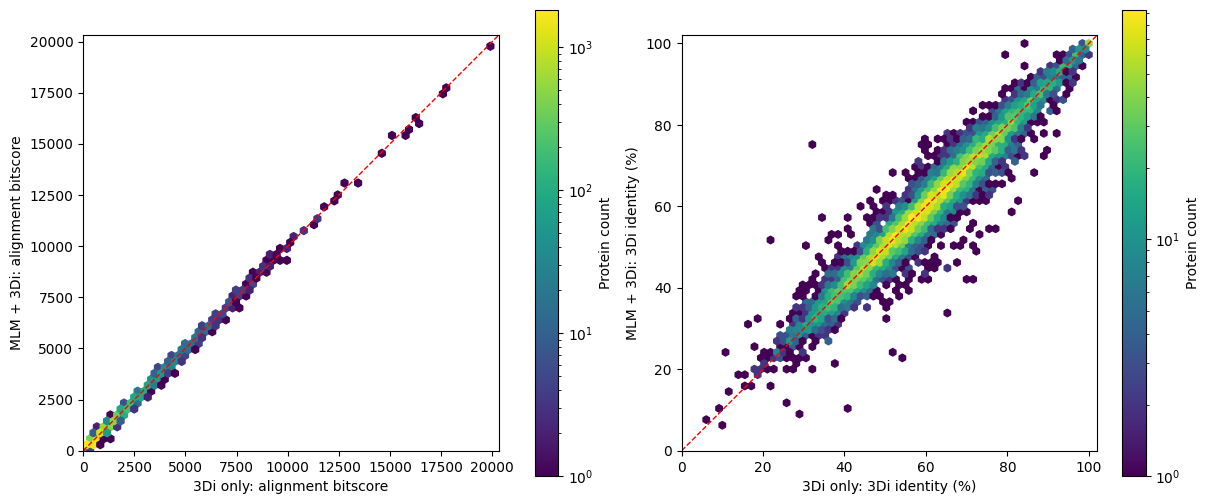

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, suffix, label in [
        (axes[0], "bits", "alignment bitscore"),
        (axes[1], "identity_pct", "3Di identity (%)")]:
    x, y = paired[f"3di_only_{suffix}"], paired[f"mlm_3di_{suffix}"]
    upper = max(x.max(), y.max()) * 1.02
    plot = ax.hexbin(x, y, gridsize=60, mincnt=1, cmap="viridis", bins="log")
    ax.plot([0, upper], [0, upper], "r--", linewidth=1)
    ax.set(xlim=(0, upper), ylim=(0, upper),
           xlabel=f"3Di only: {label}", ylabel=f"MLM + 3Di: {label}")
    ax.set_aspect("equal")
    fig.colorbar(plot, ax=ax, label="Protein count")
fig.savefig(OUTPUT / "paired_comparison.png", dpi=160)
plt.show()

## Interpretation and limitations

**2026-10-15 result:** all 10,000 proteins (2,217,405 residues) were scored.
The 3Di-only checkpoint slightly outperformed MLM + 3Di: mean per-protein
identity 60.7938% versus 60.3944% (MLM difference -0.3994 percentage points),
and mean bitscore 1112.7748 versus 1104.3969 (MLM difference -0.7529%).
MLM won identity on 3,868 proteins, lost on 4,850, and tied on 1,282.
Lower training loss did not translate into better aggregate performance here.

This is a paired **epoch-5 checkpoint** comparison on the existing MetaVR
benchmark, not a causal ablation of MLM: historical and fixed trainers also
differ in details such as training truncation (none versus 1024 tokens).
Inference settings and evaluation are identical here, so these results avoid
the incompatible loss-averaging conventions of the training logs.

AF3-derived 3Di is a predicted-structure reference, not experimental ground
truth. Dataset overlap with training has not been audited. Aggregate identity
includes all residues, without pLDDT filtering. Protein-level wins and means
are descriptive; no independence or statistical-significance claim is made.
The final checkpoints are used even if an earlier epoch has better validation
loss. Raw predictions, paired scores, source hashes, software versions, and
Foldseek logs are stored in the printed output directory.